# Utilities

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import re, string, joblib, umap, time, pickle
import numpy as np
from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# Visualization
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Hierarchical clustering
from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.spatial.distance import pdist

# Words cloud
from wordcloud import WordCloud

In [2]:
# # Basicas
# import seaborn as sns
# import os, time, pickle, pydot, joblib, kaleido, json

# from mpl_toolkits.mplot3d import Axes3D

# # Ciencia de datos
# from scipy.spatial.distance import pdist
# from sklearn.metrics.pairwise import euclidean_distances

# from sklearn.preprocessing import normalize


# from sklearn.decomposition import LatentDirichletAllocation
# from scipy.sparse import csr_matrix


# # visualizacion
# from yellowbrick.cluster import KElbowVisualizer
# import networkx as nx
# from IPython.display import Image, display
# from graphviz import Digraph

# # otros modelos
# import gensim, spacy
# # Cargar el modelo de spaCy
# nlp = spacy.load('en_core_web_sm')

# from gensim import corpora
# from gensim.models import LsiModel
# from gensim.parsing.preprocessing import preprocess_string

## Functions

In [3]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Load data

In [4]:
data = pd.read_csv('../data/input/api/data_filtered.csv')
data.shape

(4323, 7)

In [5]:
df = pd.read_csv('../data/input/api/data_cleaned.csv')
df.shape

(4323, 4)

In [6]:
df_vectorized = pd.read_csv('../data/output/df_vectorized.csv')
X = df_vectorized.values
X.shape

(4323, 14617)

In [7]:
words2remove = []

In [8]:
vectorizer = joblib.load('../models/vectorizer.pkl')
words = vectorizer.get_feature_names_out()

Dimensionality reduction

Keep 95% of explained variance

In [9]:
explained_variance_ratio_goal = 0.95
pca = PCA(n_components=explained_variance_ratio_goal)
pca.fit(df_vectorized)
n_components = pca.n_components_
n_components

1970

In [10]:
X_original = X.copy()
df_vectorized_original = df_vectorized.copy()

# X = PCA(n_components=n_components).fit_transform(X) # Specify number of components
X = pca.transform(X) # Use fitted PCA with 95% of explained variance
df_vectorized = pd.DataFrame(X)

# Normalize
X = X / np.linalg.norm(X, axis=1, keepdims=True)
df_vectorized = pd.DataFrame(X)

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


# KNN search

In [11]:
n_neighbors = 100
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine', algorithm='brute').fit(X)

# Query text

# query_text = "reinforcement learning control modular multilevel matrix converter"
# query_text = "reinforcement learning control modular power converter"
# query_text = "physics informed reinforcement learning"
# query_text = "reinforcement learning"
# query_text = "The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters."
query_text = "Control strategy, closed loop control, nested control, submodules, capacitor voltage, circulating currents, common mode voltage, voltage control, current control, energy control, power control, balancing, model predictive control, proportional integral controller, multi input multi output, modeling, total energy balance, cluster capacitor energy balance, intercluster energy balance, low frequency oscillation mitigation."
print(query_text)

# Preprocessing
query_text = [preprocess_text(query_text, words2remove)]
print(query_text)

# Vectorize
query_text_vec = pca.transform(vectorizer.transform(query_text))
print(query_text_vec)

# Calculate KNNs
knn_distances, knn_idxs = knn.kneighbors(query_text_vec.reshape(1, -1))

for i, knn_idx in enumerate(knn_idxs[0]):
    print(i)
    print(knn_idx)
    display(f"Neighbor {i+1}:")
    display(f"Title: {data['title'][knn_idx]}")
    display(f"Abstract: {data['abstract'][knn_idx]}")
    display(f"Abstract: {data['html_url'][knn_idx]}")    
    print("-"*40)

Control strategy, closed loop control, nested control, submodules, capacitor voltage, circulating currents, common mode voltage, voltage control, current control, energy control, power control, balancing, model predictive control, proportional integral controller, multi input multi output, modeling, total energy balance, cluster capacitor energy balance, intercluster energy balance, low frequency oscillation mitigation.
['control strategy closed loop control nested control submodules capacitor voltage circulating current common mode voltage voltage control current control energy control power control balancing model predictive control proportional integral controller multi input multi output modeling total energy balance cluster capacitor energy balance intercluster energy balance low frequency oscillation mitigation']
[[-0.05555374 -0.15480655  0.11790298 ...  0.00330944 -0.01242705
  -0.00514324]]
0
3251


f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


'Neighbor 1:'

'Title: nonlinear mpc based cluster energy control of modular multilevel matrix converters'

'Abstract: this paper presents an optimal reference generator of the common mode voltage and circulating currents based on a long horizon model predictive control approach to jointly perform the inter cluster capacitor voltage balancing and the low frequency oscillation mitigation to achieve cluster energy control in modular multilevel matrix converters m3c over the whole range operating frequency the block coordinate descent method is applied to the nonlinear quadratic problem to determine both variables in realtime simultaneously'

...

'Neighbor 100:'

'Title: inter arm voltage balance control of a modular multilevel matrix converter with injecting dual frequency circulating current'

'Abstract: this paper presents an inter arm capacitor voltage balance control strategy for a modular multilevel matrix converter m3c with injecting dual frequency circulating currents dfcc the proposed method enforces that the injected input frequency circulating currents and the output frequency circulating currents only flow within the nine arms of m3c under arbitrary unbalanced power transmission conditions the strategy aims to balance the energy across the nine arms to provide superior harmonic performance in both input and output grid sides even during transient processes when compared to the existing single frequency injection method comparative simulation results obtained using matlab simulink demonstrate the performance and effectiveness of the proposed control strategy'

'Abstract: https://ieeexplore.ieee.org/document/9368105/'

----------------------------------------


# Dimensionality reduction

### PCA

In [12]:
# # PCA 2D
# X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
# df['pca2d_1'] = X_pca_2d[:, 0]
# df['pca2d_2'] = X_pca_2d[:, 1]

# # PCA 3D
# X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
# df['pca3d_1'] = X_pca_3d[:, 0]
# df['pca3d_2'] = X_pca_3d[:, 1]
# df['pca3d_3'] = X_pca_3d[:, 2]

# # Graficar
# colors = np.ones(len(df))  # Color base
# colors_knn = np.zeros(len(df))  # Color para los KNN
# colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

# fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
#                     specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# # Puntos normales (fondo)
# fig.add_trace(
#     go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
#                marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                text=data['title'],
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos resaltados (delante)
# fig.add_trace(
#     go.Scatter(x=df.loc[knn_idxs[0], 'pca2d_1'], 
#                y=df.loc[knn_idxs[0], 'pca2d_2'], 
#                mode='markers',
#                marker=dict(color='red', size=5, opacity=1), 
#                text=data.loc[knn_idxs[0], 'title'], 
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos normales en 3D (fondo)
# fig.add_trace(
#     go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
#                  marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                  text=data['title'],
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# # Puntos resaltados en 3D (delante)
# fig.add_trace(
#     go.Scatter3d(x=df.loc[knn_idxs[0], 'pca3d_1'], 
#                  y=df.loc[knn_idxs[0], 'pca3d_2'], 
#                  z=df.loc[knn_idxs[0], 'pca3d_3'], 
#                  mode='markers',
#                  marker=dict(color='red', size=5, opacity=1), 
#                  text=data.loc[knn_idxs[0], 'title'], 
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
# fig.show()

### UMAP

In [13]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

# n_neighbors = 200
n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
# n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0, metric='cosine')
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0, metric='cosine')
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'umap2d_1'], 
               y=df.loc[knn_idxs[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'umap3d_1'],
                 y=df.loc[knn_idxs[0], 'umap3d_2'],
                 z=df.loc[knn_idxs[0], 'umap3d_3'],
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Plot KNN

In [14]:
reduced_zero = reducer_2d.transform(np.zeros(df_vectorized.shape[1]).reshape(1, -1))
reduced_knn = reducer_2d.transform(df_vectorized.iloc[knn_idxs[0]])
reduced_query = reducer_2d.transform(query_text_vec)

knn_distances = knn_distances.flatten()
reduced_knn.shape, reduced_query.shape, knn_distances.shape, reduced_zero

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



((100, 2), (1, 2), (100,), array([[5.807525, 2.622351]], dtype=float32))

In [15]:
knn_distances = knn_distances[::-1]

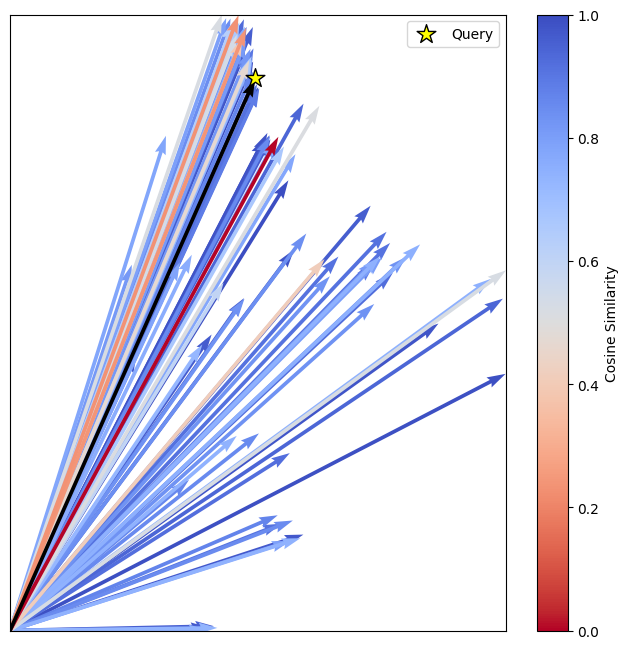

In [16]:
# Asegúrate de que las distancias estén normalizadas entre 0 y 1
exp = 1
knn_distances_normalized = (knn_distances**exp - min(knn_distances**exp)) / (max(knn_distances**exp) - min(knn_distances**exp))

# Graficar
plt.figure(figsize=(8, 8))

# Crear un mapa de colores para las distancias normalizadas
norm = plt.Normalize(vmin=0, vmax=1)  # Normalización de las distancias
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=norm)  # Invertir el colormap con "coolwarm_r"
sm.set_array([])  # Necesario para que la barra de colores funcione

# 2. Graficar los vectores de los vecinos más cercanos (KNN)
for i in range(reduced_knn.shape[0]):
    knn_point = reduced_knn[i]
    color = sm.to_rgba(knn_distances_normalized[i])  # Obtener el color correspondiente a la distancia
    plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], knn_point[0], knn_point[1], angles='xy', scale_units='xy', scale=1, color=color)

# 1. Graficar el vector de consulta (query vector)
query_point = reduced_query[0]
plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], query_point[0], query_point[1], angles='xy', scale_units='xy', scale=1, color='black')
# Añadir una estrella para el vector de consulta (usamos plt.scatter)
plt.scatter(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 1]+query_point[1], color='yellow', s=200, marker='*', label='Query', edgecolors='black')

# Configuración del gráfico
# plt.gca().set_aspect('equal', adjustable='box')
# plt.title('Query Vector and KNN Vectors')
plt.autoscale(True)
# plt.xlabel('umap2d_1')
# plt.ylabel('umap2d_2')
plt.xticks([])
plt.yticks([])
plt.xlim([min(reduced_zero[0, 0], reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].min()), max(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].max())])
plt.ylim([min(reduced_zero[0, 1], reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].min()), max(reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].max())])
plt.legend()
plt.colorbar(sm, label='Cosine Similarity', ax=plt.gca())
plt.savefig('../data/output/knn.pdf', format='pdf')
plt.show()


# Clustering

## Hierarchical

In [17]:
# methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'ward']
# metrics = ['braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'dice', 'euclidean', 'hamming', 'jaccard', 'jensenshannon', 'kulczynski1', 'mahalanobis', 'matching', 'minkowski', 'rogerstanimoto', 'russellrao', 'seuclidean', 'sokalmichener', 'sokalsneath', 'sqeuclidean', 'yule']

methods = ['average', 'complete', 'weighted', 'ward']
metrics = ['cosine', 'jensenshannon', 'correlation']

method = 'ward'
metric = 'cosine'

In [18]:
# Create hierarchical clustering with provided distance matrix
Z = linkage(X, method=method, metric=metric)

# Save clustering
joblib.dump(Z, '../data/output/hierarchical_cluster_Z.joblib')

['../data/output/hierarchical_cluster_Z.joblib']

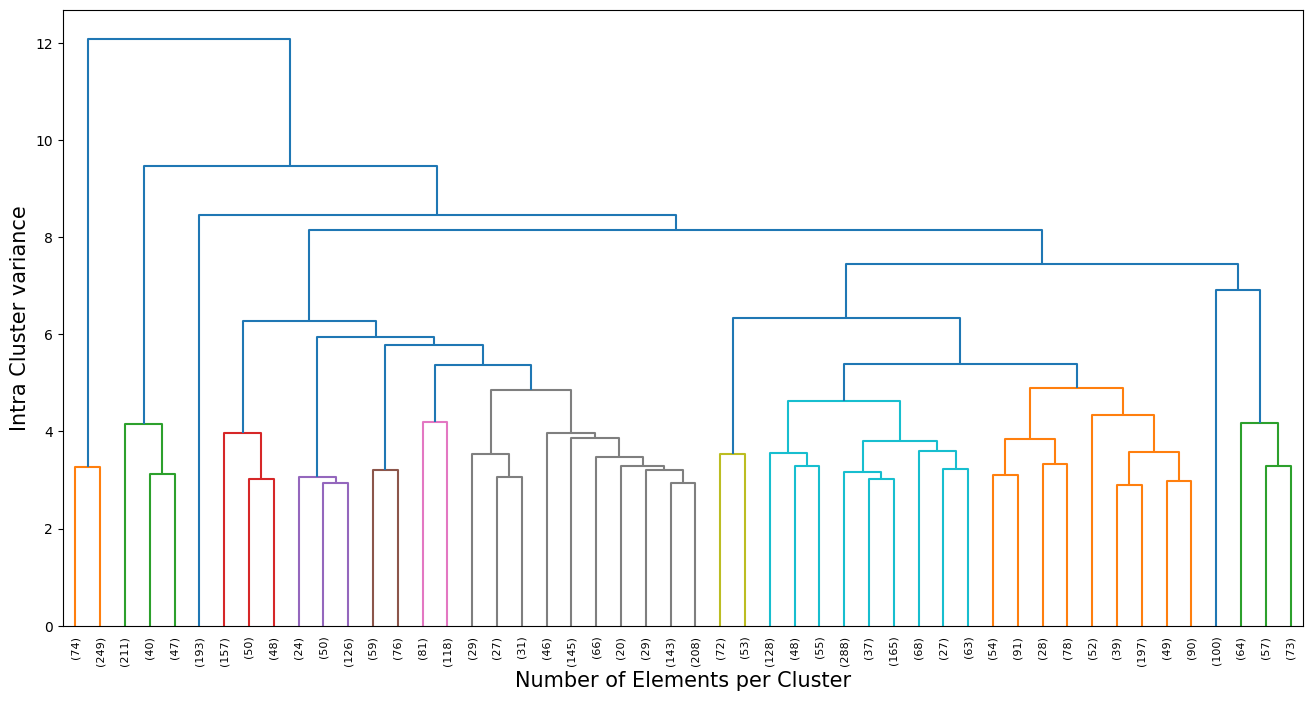

In [19]:
# Load hierarchical clustering
Z = joblib.load('../data/output/hierarchical_cluster_Z.joblib')

# Plot
plt.figure(figsize=(16, 8))
# plt.title("Hierarchical clustering dendrogram")
dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=4.96787729660)
plt.ylabel('Intra Cluster variance', size=15)
plt.xlabel('Number of Elements per Cluster', size=15)
plt.savefig('../data/output/dendrogram.pdf', format='pdf')
plt.show()

In [20]:
# Extract threshold distances for each number of clusters
def get_threshold_distances(Z, k):
    # Extract distances from linkage matrix Z (third column)
    distances = np.sort(Z[:, 2])
    
    # La distancia umbral es la (n-k)-ésima distancia en el dendrograma
    n = Z.shape[0] + 1
    if k >= n:
        return 0  # Si k es igual o mayor al número de muestras, la distancia es mínima
    
    threshold_distance = distances[-(k-1)]
    return threshold_distance

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
threshold_distances = {k: get_threshold_distances(Z, k) for k in cluster_range}

# Mostrar las distancias umbrales para cada número de clusters
display(threshold_distances)


{3: 9.459695076663138,
 4: 8.451587569466176,
 5: 8.157101375423998,
 6: 7.452818918377345,
 7: 6.90715936101093,
 8: 6.342850861858647,
 9: 6.279718524836575,
 10: 5.954287055555539,
 11: 5.77785558449198,
 12: 5.394357018498444,
 13: 5.372592197539651,
 14: 4.8872133614273485,
 15: 4.843618069534635,
 16: 4.620835950559657,
 17: 4.3476057705991344,
 18: 4.204708140940364,
 19: 4.17800013148302,
 20: 4.150307164380476,
 21: 3.977575659852515,
 22: 3.9682382672582195,
 23: 3.8606957160200333,
 24: 3.8402411600137056,
 25: 3.802057837936328,
 26: 3.5998948156788813,
 27: 3.583023965376827,
 28: 3.558112800981459,
 29: 3.542094223534863,
 30: 3.538605239753254,
 31: 3.467099912517936,
 32: 3.323342563858866,
 33: 3.2981298472981275,
 34: 3.2914840726612895,
 35: 3.2779256553358547,
 36: 3.2720838273724078,
 37: 3.23298446695313,
 38: 3.2102117422151153,
 39: 3.1963514186228075,
 40: 3.1693771763833856,
 41: 3.1222728508657838,
 42: 3.1019264774460122,
 43: 3.06555686432174,
 44: 3.062871

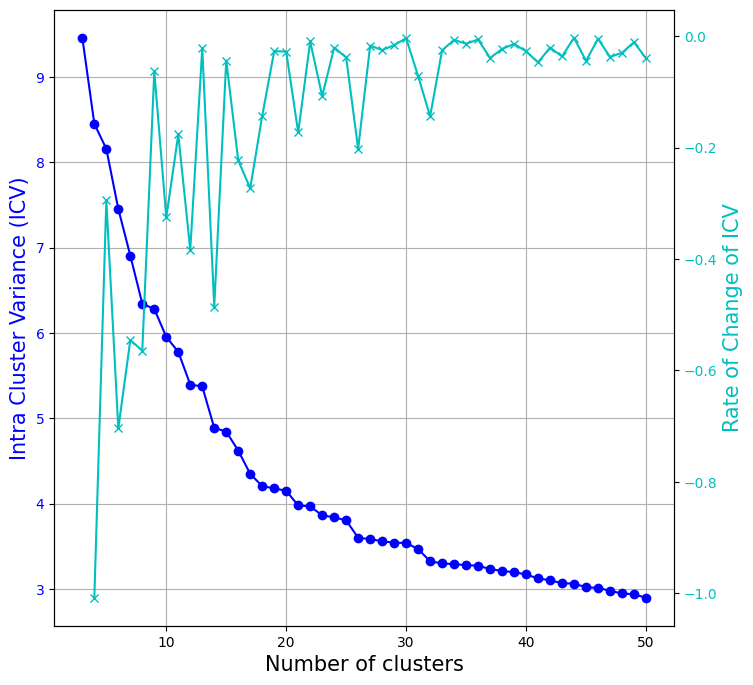

In [21]:
k_range = np.array(list(threshold_distances.keys()))
distances = np.array(list(threshold_distances.values()))
distances_dff = np.diff(distances)

# Create figure
fig, ax1 = plt.subplots(figsize=(8, 8))

# Plot threshold distances
ax1.plot(k_range, distances, marker='o', color='b', label='Threshold Distance')
ax1.set_xlabel('Number of clusters', size=15)
ax1.set_ylabel('Intra Cluster Variance (ICV)', color='b', size=15)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Plot rate of change of threshold distances
ax2 = ax1.twinx()
ax2.plot(k_range[1:], distances_dff, marker='x', color='c', label='Rate of Change of Threshold Distance')
ax2.set_ylabel('Rate of Change of ICV', color='c', size=15)
ax2.tick_params(axis='y', labelcolor='c')

# Show plot
# plt.title('Threshold Distance and Rate of Change')
plt.savefig('../data/output/elbow_method_hierarchical_clustering.pdf', format='pdf')
plt.show()

In [22]:
# # Tune threshold for level selection for hierarchical conceptual map
# k_list_concpetual_map = k_range[np.where(distances_dff < -0.5)]
# k_list_concpetual_map

In [23]:
# df_cluster = pd.DataFrame()

# df_cluster['clusters_1'] = 0

# for k in k_list_concpetual_map:
#     clusters_HC = fcluster(Z, k, criterion='maxclust') - 1
#     df_cluster[f'clusters_{k}'] = clusters_HC

# df_cluster['clusters_1'] = 0

# df_cluster

In [24]:
# for col_idx, n_clusters in enumerate(df_cluster.columns):
#     for cluster in df_cluster[n_clusters].sort_values().unique():

#         df_topic = df_vectorized_original[df_cluster[n_clusters] == cluster]
#         centroid_words = summarize(df_topic, 5)
#         print(f'Cluster {cluster} ({df_topic.shape[0]}): {centroid_words}')

#         print(f' |---- Cluster {0}')
#     print('-'*100)

Elegir cantidad de tópicos

In [49]:
k = 20
clusters = list(range(k))
print(clusters)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


In [50]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, k, criterion='maxclust') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


cluster_HC
10    657
13    648
16    375
0     323
4     255
14    251
12    231
1     211
5     200
3     193
6     135
19    130
11    125
8     118
17    100
9      87
2      87
7      81
18     64
15     52
Name: count, dtype: int64

## Kmeans

### Metodo del codo

In [51]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('data/output/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Cargar
# with open('data/output/kmeans_metrics.pkl', 'rb') as f:
#     metrics = pickle.load(f)
# inertia = metrics['inertia']
# silhouette_scores = metrics['silhouette_scores']

# # Calcular la tasa de cambio para la inercia y el Silhouette Score
# delta_inertia = np.diff(inertia)
# delta_silhouette = np.diff(silhouette_scores)

# # Crear una figura con dos subgráficos (lado a lado)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# # Graficar la inercia en el primer subgráfico (izquierda)
# ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
# ax1.set_xlabel('Número de clusters (k)')
# ax1.set_ylabel('Inercia', color='b')
# ax1.tick_params(axis='y', labelcolor='b')

# # Graficar la tasa de cambio de la inercia en el eje y derecho
# ax1_twin = ax1.twinx()
# ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
# ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
# ax1_twin.tick_params(axis='y', labelcolor='c')

# # Título y leyenda para el primer gráfico
# ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# # ax1.legend(loc='best')

# # Graficar el Silhouette Score en el segundo subgráfico (derecha)
# ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
# ax2.set_xlabel('Número de clusters (k)')
# ax2.set_ylabel('Silhouette Score', color='g')
# ax2.tick_params(axis='y', labelcolor='g')

# # Graficar la tasa de cambio del Silhouette Score en el eje y derecho
# ax2_twin = ax2.twinx()
# ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
# ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
# ax2_twin.tick_params(axis='y', labelcolor='y')

# # Título y leyenda para el segundo gráfico
# ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# # ax2.legend(loc='best')

# # Mostrar el gráfico
# plt.tight_layout()  # Ajusta el espacio entre los subgráficos
# plt.show()

### Clustering final

In [52]:
# kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X)
# df["cluster_KM"] = kmeans.predict(X)

# print(sorted(df['cluster_KM'].unique()))
# df["cluster_KM"].value_counts()

Clasificación de un texto

In [53]:
# predicted_cluster = kmeans.predict(topico_vec)
# print(predicted_cluster)

## Results

In [54]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Choose clustering type:
* cluster_HC
* cluster_KM

In [55]:
# Select clsutering method
clustering_method = "cluster_HC"

# Convert clsuter column to categorical type
df[clustering_method] = df[clustering_method].astype('category')

In [56]:
# # PCA

# # Calcular centroides de cada cluster
# centroids = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean().reset_index()

# # Crear gráfico de dispersión interactivo con leyenda discreta
# fig = px.scatter(
#     df, 
#     x='pca2d_1',
#     y='pca2d_2',
#     size=None,
#     color=clustering_method,  # Usar la columna categórica para el color
#     title='PCA 2D',
#     color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
#     hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
#     hover_name='title',  # Mostrar el título como identificador principal en el tooltip
#     opacity=0.5,
#     category_orders={clustering_method: clusters}
# )

# # Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
# fig.update_layout(
#     xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
#     yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
#     width=800,  # Establece un tamaño específico para el ancho
#     height=600,  # Establece el mismo tamaño para la altura
#     legend_title_text='Cluster'  # Personalizar el título de la leyenda
# )

# # Personalizar el formato del tooltip
# fig.update_traces(
#     marker=dict(size=5),
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
#                   "<b>X:</b> %{x}<br>" +  # Coordenada X
#                   "<b>Y:</b> %{y}<br>" +  # Coordenada Y
#                   "<extra></extra>"  # Eliminar información adicional no deseada
# )

# # Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
# fig.add_scatter(
#     x=df.loc[knn_idxs[0], 'pca2d_1'],
#     y=df.loc[knn_idxs[0], 'pca2d_2'],
#     mode='markers',
#     marker=dict(color='red', size=10, line=dict(color='black', width=2)),
#     name='KNNs',
#     showlegend=True,
#     customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
#     hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +
#                   "<b>X:</b> %{x}<br>" +
#                   "<b>Y:</b> %{y}<br>" +
#                   "<extra></extra>"
# )

# # Obtener los colores usados en el gráfico principal
# colors = px.colors.qualitative.Alphabet

# # Crear un diccionario que mapea cada cluster a un color
# cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# # Agregar centroides con el color correspondiente de su cluster
# for cluster in centroids[clustering_method]:
#     centroid = centroids[centroids[clustering_method] == cluster]
#     fig.add_scatter(
#         x=centroid['pca2d_1'],
#         y=centroid['pca2d_2'],
#         mode='markers',
#         marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
#         name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
#         showlegend=False
#     )

# # Mostrar el gráfico
# fig.show()

In [57]:
# UMAP

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean().reset_index()

# Crear gráfico de dispersión interactivo con leyenda discreta
fig = px.scatter(
    df, 
    x='umap2d_1',
    y='umap2d_2',
    size=None,
    color=clustering_method,  # Usar la columna categórica para el color
    # title='UMAP 2D',
    color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
    hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
    hover_name='title',  # Mostrar el título como identificador principal en el tooltip
    opacity=0.5,
    category_orders={clustering_method: clusters}
)

# Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
fig.update_layout(
    xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
    yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
    width=800,  # Establece un tamaño específico para el ancho
    height=800,  # Establece el mismo tamaño para la altura
    legend_title_text='Cluster',  # Personalizar el título de la leyenda
    legend_title_font_size=15,
    xaxis_title_font_size=15,
    yaxis_title_font_size=15
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=5),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
                  "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
                  "<b>X:</b> %{x}<br>" +  # Coordenada X
                  "<b>Y:</b> %{y}<br>" +  # Coordenada Y
                  "<extra></extra>"  # Eliminar información adicional no deseada
)

# Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'umap2d_1'],
    y=df.loc[knn_idxs[0], 'umap2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
    hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Obtener los colores usados en el gráfico principal
colors = px.colors.qualitative.Alphabet

# Crear un diccionario que mapea cada cluster a un color
cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# Agregar centroides con el color correspondiente de su cluster
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['umap2d_1'],
        y=centroid['umap2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
        showlegend=False
    )

# Save
fig.write_image("../data/output/UMAP.pdf")
# Mostrar el gráfico
fig.show()

C:\Users\Ingeniería Eléctrica\AppData\Local\Temp\ipykernel_4656\328979349.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



# Summarization
Importantest words by Tf-Idf score

In [58]:
def summarize(df_topic, n_centroid_words):

    # Find centroid
    centroid = df_topic.mean(axis=0)

    # Take the n first words
    centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
    
    # To list, remove duplicated words
    centroid_words = centroid_words.replace(',','').split(' ')
    centroid_words_temp = []
    for word in centroid_words:
        if word not in centroid_words_temp:
            centroid_words_temp.append(word)
    centroid_words = centroid_words_temp
    
    return centroid_words

### Corpus

In [59]:
df_topic = df_vectorized_original.copy()
centroid_words = summarize(df_topic, 10)
print(f'Full corpus: {centroid_words}')

# word_cloud(centroid_words)

Full corpus: ['voltage', 'control', 'converter', 'power', 'current', 'dc', 'multilevel', 'system', 'modular', 'mmc']


### Clusters

In [60]:
for cluster in clusters:
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    print(f'Cluster {cluster}: {", ".join(centroid_words)}')

    # word_cloud(centroid_words)

Cluster 0: wind, offshore, farm, power, voltage, control, energy, turbine, system, converter
Cluster 1: fault, dc, current, voltage, circuit, control, converter, short, system, ac
Cluster 2: fault, tolerant, voltage, detection, diagnosis, sm, control, open, converter, method
Cluster 3: predictive, control, model, mpc, voltage, current, converter, cost, function, multilevel
Cluster 4: voltage, dc, converter, transformer, power, control, ratio, high, multilevel, solid
Cluster 5: modulation, voltage, carrier, pulse, converter, width, control, switching, harmonic, level
Cluster 6: motor, voltage, drive, fluctuation, speed, frequency, control, converter, capacitor, torque
Cluster 7: sequence, current, control, unbalanced, voltage, negative, grid, condition, component, fault
Cluster 8: harmonic, circulating, current, voltage, control, controller, converter, suppression, multilevel, arm
Cluster 9: loss, thermal, temperature, sic, switching, voltage, device, power, converter, control
Cluster 1

# Hierarchical conceptual map

In [61]:
# import networkx as nx

# # Crear el grafo dirigido
# G = nx.DiGraph()

# # Ejemplo de títulos y niveles de clusters
# niveles = {
#     0: [],
#     1: ["Cluster A", "Cluster B", "Cluster C"],
#     2: ["Cluster A1", "Cluster A2", "Cluster B1", "Cluster B2", "Cluster C1"]
# }

# # Conectar los niveles de clusters
# relaciones = [
#     ('\n'.join(centroid_words), "Cluster A"),
#     ('\n'.join(centroid_words), "Cluster B"),
#     ('\n'.join(centroid_words), "Cluster C"),
#     ("Cluster A", "Cluster A1"),
#     ("Cluster A", "Cluster A2"),
#     ("Cluster B", "Cluster B1"),
#     ("Cluster B", "Cluster B2"),
#     ("Cluster C", "Cluster C1")
# ]

# # Agregar nodos y aristas al grafo
# for nivel in niveles.values():
#     G.add_nodes_from(nivel)
# G.add_edges_from(relaciones)

# # Asignar posiciones centradas a los nodos
# pos = {}
# max_width = max(len(nodos) for nodos in niveles.values())

# for nivel, nodos in niveles.items():
#     offset = (max_width - len(nodos)) / 2
#     for i, nodo in enumerate(nodos):
#         pos[nodo] = (i + offset, -nivel)

# # Dibujar el mapa conceptual jerárquico
# plt.figure(figsize=(8, 6))
# nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
# plt.title("Mapa Conceptual Jerárquico")
# plt.show()

# Documento representativo
En corpus completo y por clusters

## Centroides

In [62]:
# def encontrar_mas_cercano_al_centroide(df_vectorized, data):
#     centroide = df_vectorized.mean(axis=0)
#     distancias = euclidean_distances(df_vectorized, [centroide])
#     indice_mas_cercano = np.argmin(distancias)
#     texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
#     titulo = data.iloc[indice_mas_cercano]['title']
#     return titulo, texto_mas_cercano

### Corpus

In [63]:
# titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
# display(f"Texto mas representativo del corpus:")
# display(f"Título: {titulo}")
# display(f"Abstract: {texto_mas_cercano}")

### Clusters

In [64]:
# for cluster in clusters:
#     cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
#     cluster_data = data[df[clustering_method] == cluster]
#     titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
#     display(f"Cluster {cluster}: Texto mas cercano al centroide")
#     display(f"Título: {titulo}")
#     display(f"Abstract: {texto_mas_cercano}")

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [65]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
print("Texto más representativo del corpus:")
print(f"Título: {data['title'].iloc[abstract00]}")
print(f"Abstract: {data['abstract'].iloc[abstract00]}")

Texto más representativo del corpus:
Título: fault location method for multi terminal mmc based mvdc distribution system under dc pole to ground fault
Abstract: with the development and application of modular multilevel converter mmc hvdc technology mmc based medium voltage dc mmc mvdc distribution system is gradually attracting the attention of researchers in recent years due to its superior harmonic performance independent control of the active and reactive power rapid transient response large transmission capacity and less dc ac conversion stages it is very suitable for the future development of urban power grid in order to improve the power supply reliability and reduce the power outage time of mmc mvdc system it is usually required to operate continuously for a period of time when the dc pole to ground short circuit fault occurs therefore small current grounding method is usually used however when the pole to ground fault occurs the steady state fault current is small and the stea

### Clusters

In [66]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['title'].iloc[abstract00]}")
display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: fault location method for multi terminal mmc based mvdc distribution system under dc pole to ground fault'

'Abstract: with the development and application of modular multilevel converter mmc hvdc technology mmc based medium voltage dc mmc mvdc distribution system is gradually attracting the attention of researchers in recent years due to its superior harmonic performance independent control of the active and reactive power rapid transient response large transmission capacity and less dc ac conversion stages it is very suitable for the future development of urban power grid in order to improve the power supply reliability and reduce the power outage time of mmc mvdc system it is usually required to operate continuously for a period of time when the dc pole to ground short circuit fault occurs therefore small current grounding method is usually used however when the pole to ground fault occurs the steady state fault current is small and the steady state fault voltage is basically the same in each dc line it is difficult for the current differential protection to locate and isolate the fault a

In [67]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    display(f"Cluster {cluster}: Texto mas representativo")
    display(f"Título: {data['title'].iloc[abstract00]}")
    display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Cluster 0: Texto mas representativo'

'Título: two level suppressing controller of offshore dc overvoltage using zero sequence voltage and gfl gfm switching'

'Abstract: a valve side single phase to ground vsspg fault in the converter station of the modular multilevel converter based high voltage direct current mmc hvdc integrated offshore wind farms causes dc overvoltage in severe cases it leads to mmc blocking and off grid of the offshore wind farms to suppress dc overvoltage this article first analyzes the vsspg fault characteristics of the onshore and offshore converter stations further a two level suppressing controller of offshore dc overvoltage is proposed level i suppresses dc overvoltage peaks using fault generated zero sequence voltage components level ii utilizes the grid following gfl control and grid forming gfm control to switch between each other to achieve complete dc overvoltage suppression for permanent vsspg faults level i can be used to mitigate the system impact from overvoltage before mmc lockout for transient faults when spg faults occur at onshore converter stations the use of level i and level ii in concert with each

'Cluster 1: Texto mas representativo'

'Título: fault location method for multi terminal mmc based mvdc distribution system under dc pole to ground fault'

...

'Título: bidirectional ac dc modular multilevel converter with electric spring functions for stabilizing renewable ac power grid at the distribution voltage level'

'Abstract: bidirectional ac dc power converters are essential in emerging smart grids with increasing renewable energy penetration this article presents a bidirectional ac dc power converter system comprising modular multilevel converters mmcs and dual active bridges dabs with medium frequency transformer isolation designed for linking an ac distribution voltage of 6 6 kv to a dc grid of 800 v for future electric vehicle ev charging infrastructure the novel contributions include 1 a modular method to power ev charging infrastructures in multistorey carparks without mains frequency transformers and 2 the incorporation of a front end control with electric spring es functions that enable the dc power grid with battery energy storage to interact dynamically with the ac power grid at the distribution voltage level to achieve instantaneous power balance and hence system stability the long term aim is to use large ev charging infrastructures to stabilize increasing intermittent renewable ener

'Cluster 19: Texto mas representativo'

'Título: new modular hybrid energy storage system and its control strategy for a fuel cell locomotive'

'Abstract: a new hybrid modular converter structure is proposed for a fuel cell railway vehicle it uses a modular multilevel converter arm and a cascaded boost converter to interface the energy storage elements batteries and supercapacitors novel control architecture is presented to control energy flow between the storage blocks as well as vehicle speed based energy management system to validate the proposed converter a system was sized and simulated for the refurbishment of a class 150 dmu'

Anti representantes (abstracts con baja participación en el tfid vectorizer)

In [68]:
# representantes = [df_vectorized.loc[df[df[clustering_method] == idx].index].sum(axis=1).sort_values().index[0] for idx in clusters]
# for rep in representantes:
#   print('\nTítulo:')
#   display(data.iloc[rep]['title'])
#   print('\nAbstract')
#   display(data.iloc[rep]['Abstract'])

## Similaridad del coseno

### Corpus

In [69]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def RepresentanteCoseno(matrix_vectors):
    """
    Retorna el índice del texto más representativo del conjunto (más similar al resto).
    
    Parameters:
    - matrix_vectors: matriz (numpy array o pandas DataFrame) donde cada fila es un vector (TF-IDF o embedding)
    
    Returns:
    - Índice del texto más representativo
    """
    # Asegura que sea array de NumPy
    if hasattr(matrix_vectors, 'values'):
        matrix_vectors = matrix_vectors.values

    # Calcular matriz de similitud coseno
    similitudes = cosine_similarity(matrix_vectors)
    
    # Sumar similitudes por fila (suma de cada vector con todos los demás)
    suma_similitudes = np.sum(similitudes, axis=1)
    
    # Retornar índice del vector con mayor similitud total
    return np.argmax(suma_similitudes)


In [70]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["title"].iloc[abstract00]
abstract_mas_representativo = data["abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: a capacitor voltage balancing strategy with minimized ac circulating current for the dc dc modular multilevel converter'

'Abstract: the dc dc modular multilevel converter mmc which has originated from the ac dc mmc circuit topology is an attractive converter topology for interconnection of medium high voltage dc grids proper operation of the dc dc mmc necessitates injection of an ac circulating current to maintain its submodule sm capacitor voltages balanced the ac circulating current however needs to be minimized for efficiency improvement in addition a unique type of imbalance amongst the sm capacitor voltages that is caused by dc power flow needs to be mitigated this paper proposes a closed loop control strategy for the dc dc mmc to simultaneously regulate the dc link currents maintain the sm capacitor voltages balanced and minimize the ac circulating current performance and effectiveness of the proposed control strategy are evaluated based on simulation studies in the matlab simulink and experimentally verified on a laboratory prototype'

### Clusters

In [71]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["title"].iloc[abstract00]
    abstract_mas_representativo = data["abstract"].iloc[abstract00]
    display(f"Cluster {cluster}: Texto mas similar a todos en el cluster")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

'Cluster 0: Texto mas similar a todos en el cluster'

'Título: a hybrid cascaded transmission system suitable for large scale new energy long distance island transmission'

'Abstract: in order to meet the collection and long distance transmission of large scale wind power photovoltaic and other new energy sources in northwest china this paper proposes a sending end hybrid cascade transmission system suitable for stable transmission of large scale wind power bases firstly the topology and operation characteristics of the sending end hybrid cascaded transmission system are introduced this system has a double layer structure the high voltage valve group adopts the grid commutation converter and the low voltage valve group adopts the modular multilevel converter which can realize the access and stable delivery of large scale wind power bases then the coordinated control strategy of lcc and mmc is introduced and a coordinated start up strategy suitable for large scale wind power base access is proposed aiming at the output fluctuation of wind power base the maximum transmission power of lcc and mmc converters is analyzed respectively and the adaptive distribut

'Cluster 1: Texto mas similar a todos en el cluster'

'Título: a currentless circulating current suppressing control for modular multilevel converters'

...

'Título: a broad range of frequency control for the modular multilevel cascade converter based on triple star bridge cells mmcc tsbc'

'Abstract: this paper focuses on an application of the modular multilevel cascade converter based on triple star bridge cells mmcc tsbc to adjustable speed motor drives the tsbc is one of direct ac to ac power converters capable of bidirectional power flow with three phase sinusoidal input and output currents therefore it is suitable to medium voltage high power motor drives requiring regenerative braking this paper designs constructs and tests a three phase 400 v 15 kw downscaled model with four bridge cells per cluster adopting the so called phase shifted pwm to produce multilevel waveforms at both sides good operating performance is verified by some experimental results obtained from the downscaled model on the other hand the tsbc suffers from such a serious problem that capacitor voltage fluctuation becomes larger as the motor output frequency is closer to the supply input frequency this paper also has an intensive discussion on how to control the tsbc intended for achieving a broa

'Cluster 19: Texto mas similar a todos en el cluster'

'Título: a decoupled energy control strategy for the series bridge converter sbc for hvdc applications'

'Abstract: the series bridge converter sbc is a new modular multilevel topology for hvdc featuring a highly compact footprint that makes it attractive for offshore and city infeed applications size reduction is achieved with a lower number of cells with smaller cell capacitors compared to other state of art topologies thus reducing the total energy storage as a drawback the sbc has a more challenging control in particular care must be taken to guarantee consistent and predictable dynamic response of the energy controllers this paper proposes a simple energy control scheme for the sbc based on a coordinate transformation that guarantees independent control of the energy stored in each arm and simplifies the design and implementation of the energy loops the effectiveness of the controllers has been validated with a matlab plecs switching simulation model'

# Grafo de palabras

## Palabras de un abstract especifico

In [72]:
# # Obtener el texto del dataframe
# texto = df.iloc[1000]["abstract"]

# # Procesar el texto con spaCy
# doc = nlp(texto)

# # Crear grafo dirigido con NetworkX
# G = nx.DiGraph()
# for token in doc:
#     if not token.is_stop and not token.is_punct:
#         G.add_node(token.text)
#     for child in token.children:
#         if not child.is_stop and not child.is_punct:
#             G.add_edge(token.text, child.text)

# # Calcular importancia con PageRank
# pagerank = nx.pagerank(G)

# # Crear el grafo con Graphviz
# dot = Digraph(format="png")
# dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# # Agregar nodos con tamaño basado en PageRank
# max_pr = max(pagerank.values()) if pagerank else 1
# for node, pr in pagerank.items():
#     size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
#     dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# # Agregar aristas
# for u, v in G.edges():
#     dot.edge(u, v, color="black", penwidth="1.5")

# # Renderizar el grafo en un archivo temporal
# output_file = "Data/Figuras/grafo"
# dot.render(output_file, format="png", cleanup=True)
# # Mostrar la imagen en Jupyter Notebook
# display(Image(filename=output_file + ".png"))

## Entre clusters